In [2]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Sun Aug 16 23:28:21 2026

@author: jeferson
"""

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, log_loss
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

In [3]:
### Import dataset
data = pd.read_csv('/home/jeferson/Documentos/Curso Ciência de Dados USP 2026/Projetos/data/open_supply-curve_post_proc.csv')

### Data Exploration
print('Number of rows and columns: ', data.shape)
data.head(10)

# print(data.dtypes)
# print(data.isna().sum())

# DataFrame Construction
df = data[
    [
        'mean_depth',  # Average water depth at the site (meters)
        'dist_to_coast_offshore',  # Distance from site to nearest coastline (km)
        'resource',  # Estimated annual average wind resource at the site (m/s)
        'technology',  # Turbine foundation technology type (e.g., fixed-bottom=0 or floating=1)
    ]
].copy()

# Convert text column to numeric values inside the same column
df['technology'] = df['technology'].astype('category').cat.codes

# Data description
df.describe()

Number of rows and columns:  (4643, 27)


,mean_depth,dist_to_coast_offshore,resource,technology
count,4643.000000,4643.000000,4643.000000,4643.000000
mean,362.830684,88.375869,7.937556,0.660564
std,410.217434,72.655188,1.227955,0.473569
min,6.000000,0.000000,3.210638,0.000000
25%,41.298327,29.778613,7.061746,0.000000
50%,141.356920,65.172324,7.880521,1.000000
75%,723.044770,133.396035,8.857931,1.000000
max,1299.000000,355.922200,11.332843,1.000000


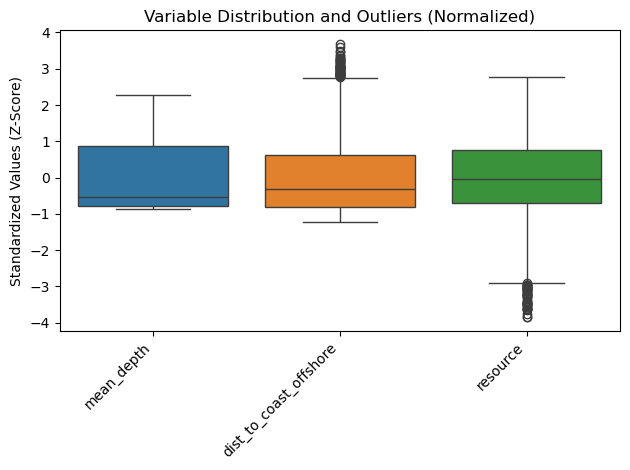

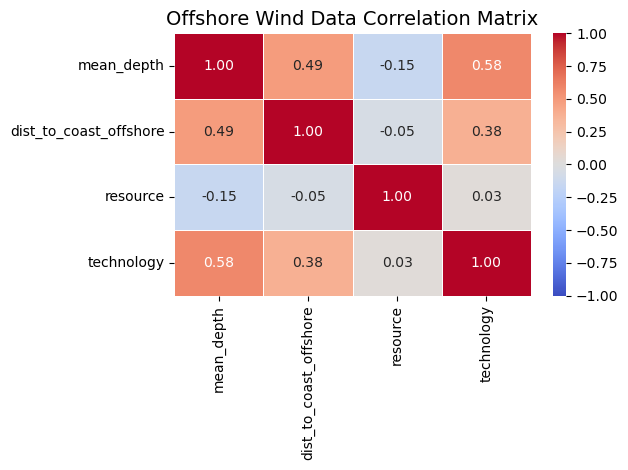

In [2]:
### Data Visualization

# Boxplot
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

# Data Standardization (Mean = 0, Standard Deviation = 1)
scaler = StandardScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df[numeric_cols]), columns=numeric_cols
)

# Standardized Boxplot
plt.figure()
sns.boxplot(data=df_scaled)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Standardized Values (Z-Score)')
plt.title('Variable Distribution and Outliers (Normalized)')
plt.tight_layout()
plt.show()

# Correlation Matrix
correlation_matrix = df.corr()

# Visual Heatmap
plt.figure()
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title('Offshore Wind Data Correlation Matrix', fontsize=14)
plt.tight_layout()
plt.show()

=== Target Variable Distribution (technology) ===
Absolute counts:
technology
1    3067
0    1576
Name: count, dtype: int64

Percentage proportion:
technology
1    66.0564
0    33.9436
Name: proportion, dtype: float64


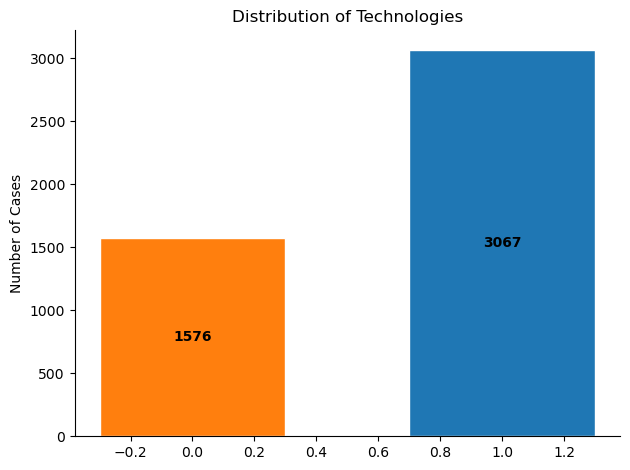

In [3]:
### =============================================================================
### CLASSIFICATION MODELS SETUP
### =============================================================================

# Data (X, y)
X = df[["mean_depth", "dist_to_coast_offshore", "resource"]]
y = df["technology"]

# Check for target variable imbalance
print("=== Target Variable Distribution (technology) ===")
counts = df["technology"].value_counts()
proportions = df["technology"].value_counts(normalize=True)
# 
print("Absolute counts:")
print(counts)
print("\nPercentage proportion:")
print((proportions * 100).round(4))

# Plot
fig, ax = plt.subplots()
cmap = plt.colormaps.get_cmap('tab10')  
bar_colors = [cmap(i) for i in range(len(counts))]
ax.bar(counts.index, counts.values, color=bar_colors, edgecolor="white", width=0.6)
ax.set_ylabel("Number of Cases")
ax.set_title("Distribution of Technologies")
for category, v in counts.items():
    ax.text(
        category,
        v / 2,            
        str(v),            
        ha="center",       
        va="center",       
        color="black",     
        fontweight='bold'
    )
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

# Training and Testing Sets Split (Stratified for Classification)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Define Stratified K-Fold Cross-Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Metrics (scoring)
#
# Accuracy: "accuracy" (dataset  ~50%/50% up to 60%/40%)
# Curva ROC: "roc_auc" (dataset  ~70%/30% up to 80%/20%)
# F1-Score: "f1" ou "f1_macro" (dataset more than 90% or 95%)
# Precision: "precision" (dataset more than 90% or 95%)
# Entropia Cruzada: "neg_log_loss"
# etc
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]


[INFO] Running GridSearchCV for K-NN Classifier...
------------------------------------------------------------
OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (K-NN)
------------------------------------------------------------
Best Number of Neighbors (k): 10
Best Cross-Validation Accuracy: 0.9973
------------------------------------------------------------


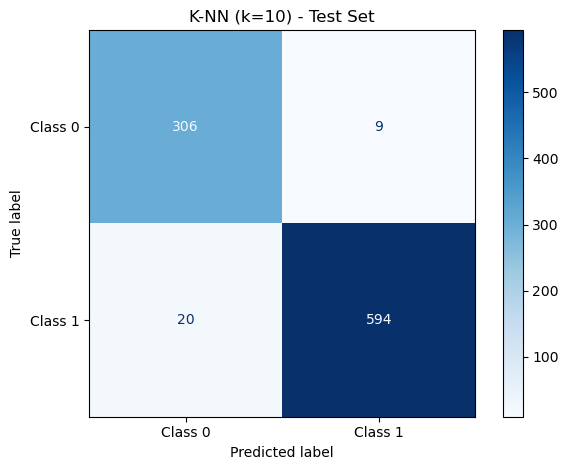

In [4]:
# =============================================================================
# MODEL 1: K-NEAREST NEIGHBORS (K-NN) CLASSIFIER
# =============================================================================
print("\n[INFO] Running GridSearchCV for K-NN Classifier...")

knn_pipeline = Pipeline(
    [("scaler", StandardScaler()), 
     ("model", KNeighborsClassifier())]
)

knn_param_grid = {
    'model__n_neighbors': [3, 5, 10, 20, 40],
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan']
}

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=skf,
    scoring="roc_auc",
    # refit="roc_auc",  
    return_train_score=True,
)

knn_grid.fit(X_train, y_train)

best_k = knn_grid.best_params_["model__n_neighbors"]
best_knn_cv_acc = knn_grid.best_score_

print("-" * 60)
print("OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (K-NN)")
print("-" * 60)
print(f"Best Number of Neighbors (k): {best_k}")
print(f"Best Cross-Validation Accuracy: {best_knn_cv_acc:.4f}")
print("-" * 60)

# Evaluate on Test Set
best_knn_model = knn_grid.best_estimator_
y_pred_knn = best_knn_model.predict(X_test)
y_proba_knn = best_knn_model.predict_proba(X_test)[:, 1]  # Probabilities for class 1

knn_acc = accuracy_score(y_test, y_pred_knn)
knn_prec = precision_score(y_test, y_pred_knn, zero_division=0)
knn_rec = recall_score(y_test, y_pred_knn, zero_division=0)
knn_f1 = f1_score(y_test, y_pred_knn, zero_division=0)

# Confusion Matrix Plot
fig, ax = plt.subplots()
cm_knn = confusion_matrix(y_test, y_pred_knn)
disp_knn = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn, display_labels=["Class 0", "Class 1"]
)
disp_knn.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title(f"K-NN (k={best_k}) - Test Set")
plt.tight_layout()
plt.show()


[INFO] Running GridSearchCV for Decision Tree Classifier...
------------------------------------------------------------
OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (DECISION TREE)
------------------------------------------------------------
Best Max Depth:                 None
Best Cross-Validation Accuracy: 0.9996
------------------------------------------------------------


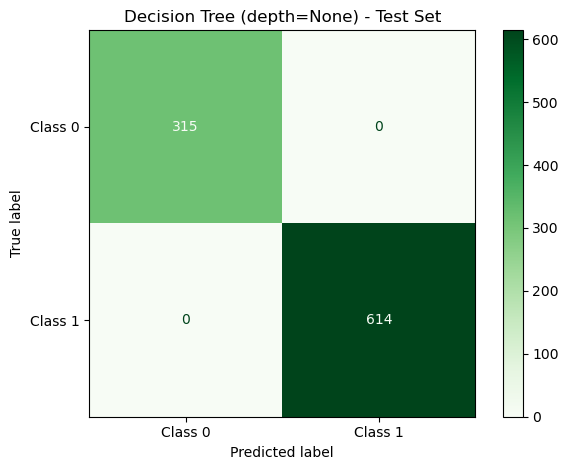

In [5]:
# =============================================================================
# MODEL 2: DECISION TREE CLASSIFIER
# =============================================================================
print("\n[INFO] Running GridSearchCV for Decision Tree Classifier...")

dt_pipeline = Pipeline(
    [("scaler", StandardScaler()), 
     ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))]
)

dt_param_grid = {
    'model__max_depth': [None, 3, 5, 10, 15],
    'model__criterion': ['gini', 'entropy'],
    'model__min_samples_leaf': [1, 2, 5, 10]
}

dt_grid = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_param_grid,
    cv=skf,
    scoring="roc_auc",
    # refit="roc_auc",
    return_train_score=True,
)

dt_grid.fit(X_train, y_train)

best_depth = dt_grid.best_params_["model__max_depth"]
best_dt_cv_acc = dt_grid.best_score_

print("-" * 60)
print("OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (DECISION TREE)")
print("-" * 60)
print(f"Best Max Depth:                 {best_depth}")
print(f"Best Cross-Validation Accuracy: {best_dt_cv_acc:.4f}")
print("-" * 60)

# Evaluate on Test Set
best_dt_model = dt_grid.best_estimator_
y_pred_dt = best_dt_model.predict(X_test)
y_proba_dt = best_dt_model.predict_proba(X_test)[:, 1]  # Probabilities for class 1

dt_acc = accuracy_score(y_test, y_pred_dt)
dt_prec = precision_score(y_test, y_pred_dt, zero_division=0)
dt_rec = recall_score(y_test, y_pred_dt, zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, zero_division=0)

# Confusion Matrix Plot
fig, ax = plt.subplots()
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt, display_labels=["Class 0", "Class 1"])
disp_dt.plot(ax=ax, cmap="Greens", values_format="d")
ax.set_title(f"Decision Tree (depth={best_depth}) - Test Set")
plt.tight_layout()
plt.show()



[INFO] Running GridSearchCV for Random Forest Classifier...
------------------------------------------------------------
OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (RANDOM FOREST)
------------------------------------------------------------
Best Max Depth:                 None
Best N Estimators:              300
Best Cross-Validation ROC AUC:  1.0000
------------------------------------------------------------


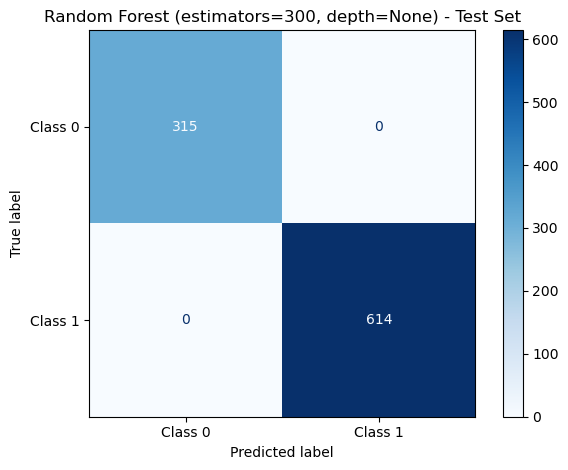


[INFO] Generating Feature Importance for Random Forest Classifier...


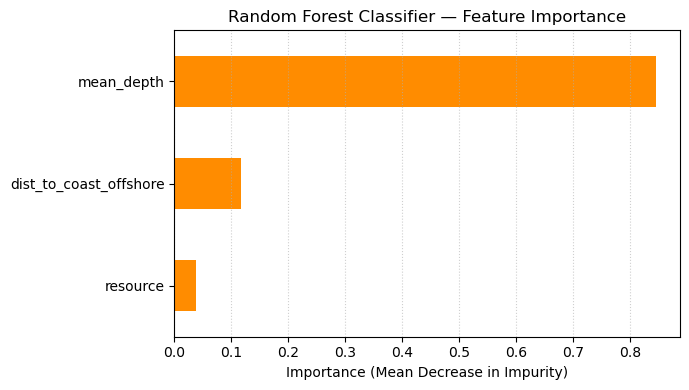

In [6]:
# =============================================================================
# MODEL 3: RANDOM FOREST CLASSIFIER
# =============================================================================
print("\n[INFO] Running GridSearchCV for Random Forest Classifier...")

rf_pipeline = Pipeline(
    [("scaler", StandardScaler()), 
     ("model", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE))]
)

rf_param_grid = {
    'model__n_estimators': [50, 100, 200, 300],
    'model__max_depth': [None, 5, 10, 15],
    'model__criterion': ['gini', 'entropy'],
    'model__min_samples_leaf': [1, 2, 5]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=skf,
    scoring="roc_auc",
    # refit="roc_auc",
    return_train_score=True,
)

rf_grid.fit(X_train, y_train)

best_rf_depth = rf_grid.best_params_["model__max_depth"]
best_rf_estimators = rf_grid.best_params_["model__n_estimators"]
best_rf_cv_auc = rf_grid.best_score_

print("-" * 60)
print("OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (RANDOM FOREST)")
print("-" * 60)
print(f"Best Max Depth:                 {best_rf_depth}")
print(f"Best N Estimators:              {best_rf_estimators}")
print(f"Best Cross-Validation ROC AUC:  {best_rf_cv_auc:.4f}")
print("-" * 60)

# Evaluate on Test Set
best_rf_model = rf_grid.best_estimator_
y_pred_rf = best_rf_model.predict(X_test)
y_proba_rf = best_rf_model.predict_proba(X_test)[:, 1]  # Probabilities for class 1

rf_acc = accuracy_score(y_test, y_pred_rf)
rf_prec = precision_score(y_test, y_pred_rf, zero_division=0)
rf_rec = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)

# Confusion Matrix Plot
fig, ax = plt.subplots()
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf, display_labels=["Class 0", "Class 1"])
disp_rf.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title(f"Random Forest (estimators={best_rf_estimators}, depth={best_rf_depth}) - Test Set")
plt.tight_layout()
plt.show()

# Feature Importance for Classifier 
print("\n[INFO] Generating Feature Importance for Random Forest Classifier...")
#
# Extract the fitted model from the pipeline and the column names
rf_features = X_train.columns if hasattr(X_train, 'columns') else [f"Feature {i}" for i in range(X_train.shape[1])]
best_rf_clf = best_rf_model.named_steps["model"]

# Create a Series containing feature importances
importances_clf = pd.Series(best_rf_clf.feature_importances_, index=rf_features)
importances_clf = importances_clf.sort_values(ascending=False)

# 3. Plot horizontal bar chart
plt.figure(figsize=(7, 4))
importances_clf.plot(kind='barh', color='darkorange')
plt.gca().invert_yaxis()  
plt.xlabel('Importance (Mean Decrease in Impurity)')
plt.title('Random Forest Classifier — Feature Importance')
plt.grid(True, axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


[INFO] Running GridSearchCV for Regularized Logistic Regression Classifier...
------------------------------------------------------------
OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (LOGISTIC REGRESSION)
------------------------------------------------------------
Best Solver Used:                liblinear
Best C (Inverse Regularization): 10
Best Penalty Type:               l1
Best Cross-Validation ROC AUC:   1.0000
------------------------------------------------------------


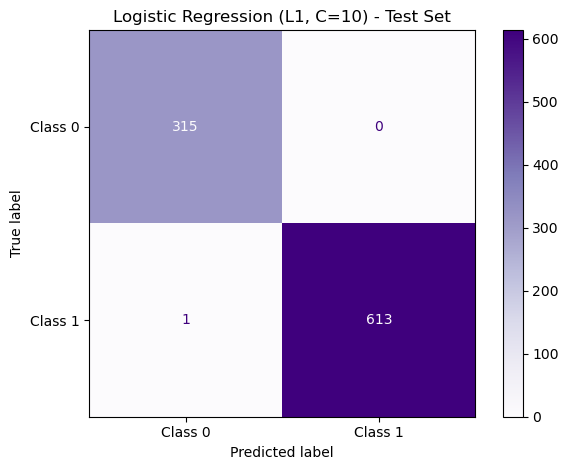

In [7]:
# =============================================================================
# MODEL 4: LOGISTIC REGRESSION CLASSIFIER WITH REGULARIZATION (L1, L2, ELASTICNET)
# =============================================================================
print("\n[INFO] Running GridSearchCV for Regularized Logistic Regression Classifier...")

# Define the Pipeline
# class_weight, random_state, and max_iter will be preserved by overriding options in param_grid
lr_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()), 
        ("model", LogisticRegression(class_weight="balanced", random_state=RANDOM_STATE, max_iter=5000))
    ]
)

# Hyperparameter search space configuration
c_values = [0.1, 1, 10]

# List of parameter dictionaries to handle solver-specific compatibility
lr_param_grid = [
    # Configuration A: L1 (Lasso) and L2 (Ridge) using 'liblinear' solver
    {
        'model__solver': ['liblinear'],
        'model__C': c_values,
        'model__penalty': ['l1', 'l2']
    },
    # Configuration B: Elastic Net using 'saga' solver (required for l1_ratio)
    {
        'model__solver': ['saga'],
        'model__C': c_values,
        'model__penalty': ['elasticnet'],
        'model__l1_ratio': [0.2, 0.5, 0.8] # Mixing parameter between L1 and L2
    }
]

# Configure GridSearchCV with parallel processing enabled (n_jobs=-1)
lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    cv=skf,
    scoring="roc_auc",
    return_train_score=True,
    n_jobs=-1
)

# Run hyperparameter search using training data
lr_grid.fit(X_train, y_train)

# Extract optimal parameter values found
best_params = lr_grid.best_params_
best_c = best_params["model__C"]
best_penalty = best_params["model__penalty"]
best_solver = best_params["model__solver"]
best_lr_cv_auc = lr_grid.best_score_

print("-" * 60)
print("OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (LOGISTIC REGRESSION)")
print("-" * 60)
print(f"Best Solver Used:                {best_solver}")
print(f"Best C (Inverse Regularization): {best_c}")
print(f"Best Penalty Type:               {best_penalty}")
if "model__l1_ratio" in best_params:
    print(f"Best L1 Ratio (ElasticNet):      {best_params['model__l1_ratio']}")
print(f"Best Cross-Validation ROC AUC:   {best_lr_cv_auc:.4f}")
print("-" * 60)

# Evaluate on Test Set using the automatically refitted best estimator
best_lr_model = lr_grid.best_estimator_
y_pred_lr = best_lr_model.predict(X_test)
y_proba_lr = best_lr_model.predict_proba(X_test)[:, 1]

lr_acc = accuracy_score(y_test, y_pred_lr)
lr_prec = precision_score(y_test, y_pred_lr, zero_division=0)
lr_rec = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)

# CONFUSION MATRICES PLOT
fig, ax = plt.subplots()
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr, display_labels=["Class 0", "Class 1"])
disp_lr.plot(ax=ax, cmap="Purples", values_format="d")

# Dynamically building the title depending on the selected penalty type
penalty_title = f"{best_penalty.upper()}"
if best_penalty == "elasticnet":
    penalty_title += f" (l1_ratio={best_params['model__l1_ratio']})"

ax.set_title(f"Logistic Regression ({penalty_title}, C={best_c}) - Test Set")
plt.tight_layout()
plt.show()



[INFO] Running GridSearchCV for Multilayer Perceptron Classifier...
------------------------------------------------------------
OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (MLP CLASSIFIER)
------------------------------------------------------------
Best Hidden Layer Sizes:         (50,)
Best Activation Function:       tanh
Best Alpha (L2 Regularization): 0.0001
Best Cross-Validation ROC AUC:   1.0000
------------------------------------------------------------


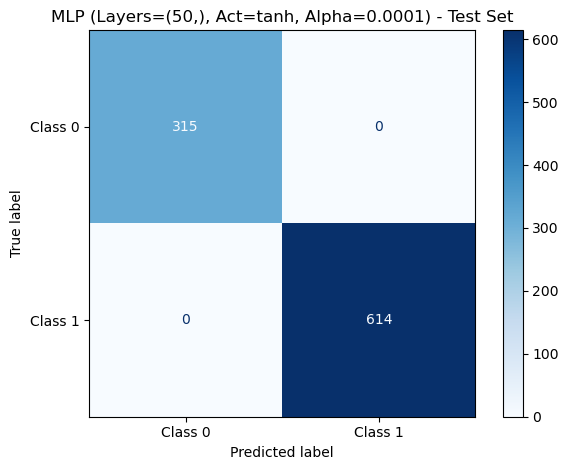


[INFO] Generating epoch-by-epoch Training vs. Validation curves...


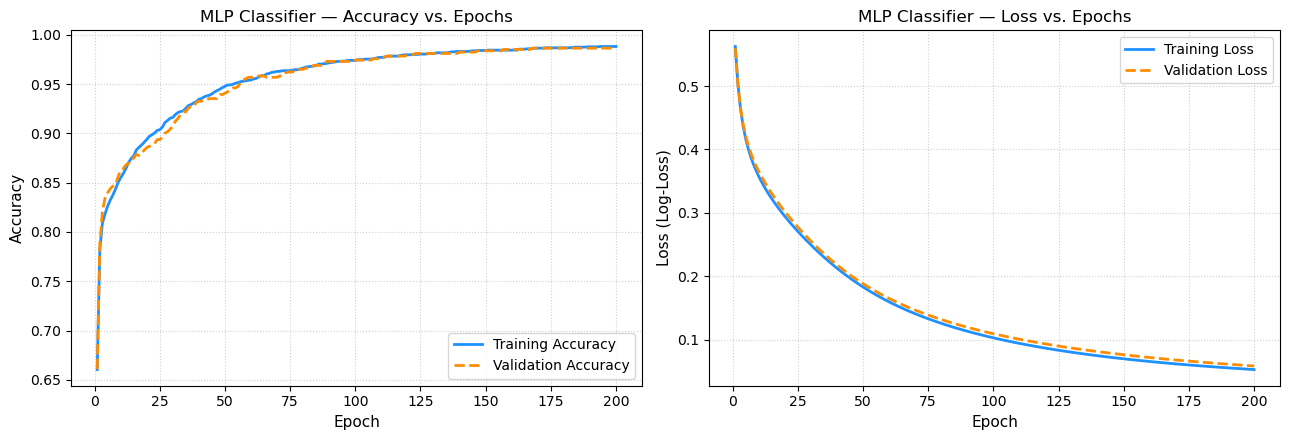

In [8]:
# =============================================================================
# MODEL 5: MULTILAYER PERCEPTRON (MLP) CLASSIFIER
# =============================================================================
print("\n[INFO] Running GridSearchCV for Multilayer Perceptron Classifier...")

# Define the Pipeline
mlp_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(solver="adam", max_iter=2000, random_state=RANDOM_STATE))
    ]
)

# Hyperparameter search space configuration
mlp_param_grid = {
    'model__hidden_layer_sizes': [(50,), (100,), (50, 50), (100, 50)],
    'model__activation': ['tanh', 'relu'],
    'model__alpha': [1e-4, 1e-3, 1e-2]
}

# Configure GridSearchCV com parallel processing e a métrica ROC AUC
mlp_grid = GridSearchCV(
    estimator=mlp_pipeline,
    param_grid=mlp_param_grid,
    cv=skf,
    scoring="roc_auc",
    return_train_score=True,
    n_jobs=-1
)

# Run hyperparameter search using training data 
mlp_grid.fit(X_train, y_train)

# Extract optimal parameter values found
best_mlp_params = mlp_grid.best_params_
best_hidden_layers = best_mlp_params["model__hidden_layer_sizes"]
best_activation = best_mlp_params["model__activation"]
best_alpha = best_mlp_params["model__alpha"]
best_mlp_cv_auc = mlp_grid.best_score_

print("-" * 60)
print("OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (MLP CLASSIFIER)")
print("-" * 60)
print(f"Best Hidden Layer Sizes:         {best_hidden_layers}")
print(f"Best Activation Function:       {best_activation}")
print(f"Best Alpha (L2 Regularization): {best_alpha}")
print(f"Best Cross-Validation ROC AUC:   {best_mlp_cv_auc:.4f}")
print("-" * 60)

# Evaluate on Test Set using the automatically refitted best estimator
best_mlp_model = mlp_grid.best_estimator_
y_pred_mlp = best_mlp_model.predict(X_test)
y_proba_mlp = best_mlp_model.predict_proba(X_test)[:, 1]

mlp_acc = accuracy_score(y_test, y_pred_mlp)
mlp_prec = precision_score(y_test, y_pred_mlp, zero_division=0)
mlp_rec = recall_score(y_test, y_pred_mlp, zero_division=0)
mlp_f1 = f1_score(y_test, y_pred_mlp, zero_division=0)

# Confusion Matrix Plot 
fig, ax = plt.subplots()
cm_mlp = confusion_matrix(y_test, y_pred_mlp)
disp_mlp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp, display_labels=["Class 0", "Class 1"])
disp_mlp.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title(f"MLP (Layers={best_hidden_layers}, Act={best_activation}, Alpha={best_alpha}) - Test Set")
plt.tight_layout()
plt.show()

# MLP Convergence Analysis
print("\n[INFO] Generating epoch-by-epoch Training vs. Validation curves...")

# Split X_train into Train and Validation sets for monitoring
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train
)

# Scale features manually to prevent leakage during partial_fit
scaler_epoch = StandardScaler()
X_tr_scaled = scaler_epoch.fit_transform(X_tr)
X_val_scaled = scaler_epoch.transform(X_val)

# Instantiate MLPClassifier using best hyperparams with SGD/Adam for partial_fit
best_mlp_epoch = MLPClassifier(
    hidden_layer_sizes=best_hidden_layers,
    activation=best_activation,
    alpha=best_alpha,
    solver="adam",
    random_state=RANDOM_STATE
)

# Initialize tracking lists
train_loss_history, val_loss_history = [], []
train_acc_history, val_acc_history = [], []

epochs_count = 200
classes = np.unique(y_train)

# Epoch loop using partial_fit
for epoch in range(epochs_count):
    best_mlp_epoch.partial_fit(X_tr_scaled, y_tr, classes=classes)

    # Predictions & Probabilities
    y_tr_pred = best_mlp_epoch.predict(X_tr_scaled)
    y_val_pred = best_mlp_epoch.predict(X_val_scaled)

    y_tr_proba = best_mlp_epoch.predict_proba(X_tr_scaled)
    y_val_proba = best_mlp_epoch.predict_proba(X_val_scaled)

    # Compute Epoch Metrics
    train_acc_history.append(accuracy_score(y_tr, y_tr_pred))
    val_acc_history.append(accuracy_score(y_val, y_val_pred))

    train_loss_history.append(log_loss(y_tr, y_tr_proba))
    val_loss_history.append(log_loss(y_val, y_val_proba))

epochs_range = range(1, epochs_count + 1)

# Convergence Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
#
# Accuracy Plot
ax1.plot(epochs_range, train_acc_history, label="Training Accuracy", color="dodgerblue", lw=2)
ax1.plot(epochs_range, val_acc_history, label="Validation Accuracy", color="darkorange", lw=2, linestyle="--")
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Accuracy", fontsize=11)
ax1.set_title("MLP Classifier — Accuracy vs. Epochs", fontsize=12)
ax1.legend(loc="lower right", fontsize=10)
ax1.grid(True, linestyle=":", alpha=0.6)
#
# Loss Plot
ax2.plot(epochs_range, train_loss_history, label="Training Loss", color="dodgerblue", lw=2)
ax2.plot(epochs_range, val_loss_history, label="Validation Loss", color="darkorange", lw=2, linestyle="--")
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Loss (Log-Loss)", fontsize=11)
ax2.set_title("MLP Classifier — Loss vs. Epochs", fontsize=12)
ax2.legend(loc="upper right", fontsize=10)
ax2.grid(True, linestyle=":", alpha=0.6)
#
plt.tight_layout()
plt.show()

In [9]:
# =============================================================================
# FINAL PERFORMANCE COMPARISON TABLE
# =============================================================================
print("\n" + "=" * 130)
print("FINAL PERFORMANCE COMPARISON (TEST DATASET)")
print("=" * 130)
print(f"{'Metric':<12} | {'K-NN Classifier':<18} | {'Decision Tree':<18} | {'Logistic Regression':<20} | {'Random Forest':<18} | {'MLP Classifier':<18}")
print("-" * 130)
print(f"{'Accuracy':<12} | {knn_acc:<18.4f} | {dt_acc:<18.4f} | {lr_acc:<20.4f} | {rf_acc:<18.4f} | {mlp_acc:<18.4f}")
print(f"{'Precision':<12} | {knn_prec:<18.4f} | {dt_prec:<18.4f} | {lr_prec:<20.4f} | {rf_prec:<18.4f} | {mlp_prec:<18.4f}")
print(f"{'Recall':<12} | {knn_rec:<18.4f} | {dt_rec:<18.4f} | {lr_rec:<20.4f} | {rf_rec:<18.4f} | {mlp_rec:<18.4f}")
print(f"{'F1-Score':<12} | {knn_f1:<18.4f} | {dt_f1:<18.4f} | {lr_f1:<20.4f} | {rf_f1:<18.4f} | {mlp_f1:<18.4f}")
print("=" * 130)


FINAL PERFORMANCE COMPARISON (TEST DATASET)
Metric       | K-NN Classifier    | Decision Tree      | Logistic Regression  | Random Forest      | MLP Classifier    
----------------------------------------------------------------------------------------------------------------------------------
Accuracy     | 0.9688             | 1.0000             | 0.9989               | 1.0000             | 1.0000            
Precision    | 0.9851             | 1.0000             | 1.0000               | 1.0000             | 1.0000            
Recall       | 0.9674             | 1.0000             | 0.9984               | 1.0000             | 1.0000            
F1-Score     | 0.9762             | 1.0000             | 0.9992               | 1.0000             | 1.0000            


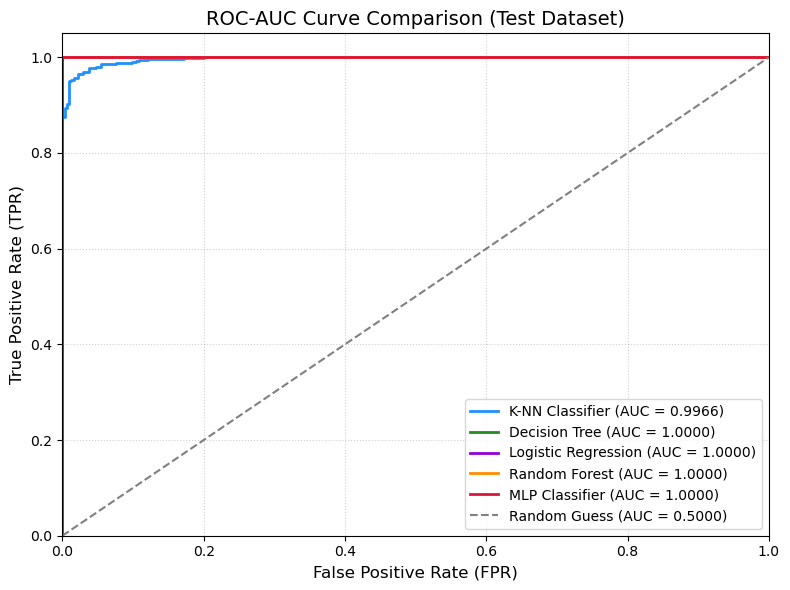

In [10]:
# =============================================================================
# ROC-AUC CURVE COMPARISON PLOT
# =============================================================================
plt.figure(figsize=(8, 6))

# Compute ROC curve and AUC for K-NN
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_proba_knn)
auc_knn = auc(fpr_knn, tpr_knn)
plt.plot(fpr_knn, tpr_knn, color='dodgerblue', lw=2, label=f'K-NN Classifier (AUC = {auc_knn:.4f})')

# Compute ROC curve and AUC for Decision Tree
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_proba_dt)
auc_dt = auc(fpr_dt, tpr_dt)
plt.plot(fpr_dt, tpr_dt, color='forestgreen', lw=2, label=f'Decision Tree (AUC = {auc_dt:.4f})')

# Compute ROC curve and AUC for Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
auc_lr = auc(fpr_lr, tpr_lr)
plt.plot(fpr_lr, tpr_lr, color='darkviolet', lw=2, label=f'Logistic Regression (AUC = {auc_lr:.4f})')

# Compute ROC curve and AUC for Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
auc_rf = auc(fpr_rf, tpr_rf)
plt.plot(fpr_rf, tpr_rf, color='darkorange', lw=2, label=f'Random Forest (AUC = {auc_rf:.4f})')

# Compute ROC curve and AUC for MLP Classifier <--- ADICIONADO
fpr_mlp, tpr_mlp, _ = roc_curve(y_test, y_proba_mlp)
auc_mlp = auc(fpr_mlp, tpr_mlp)
plt.plot(fpr_mlp, tpr_mlp, color='crimson', lw=2, label=f'MLP Classifier (AUC = {auc_mlp:.4f})')

# Plot Random Guess Line
plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Guess (AUC = 0.5000)')

# Formatting details
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('ROC-AUC Curve Comparison (Test Dataset)', fontsize=14)
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()